|<h2>Book:</h2>|<h1><a href="https://open.substack.com/pub/mikexcohen/p/llm-breakdown-16-tokenization-words" target="_blank">50 ML projects to understand LLMs</a></h1>|
|-|:-:|
|<h2>Project:</h2>|<h1><b>[25] Category selectivity via cosine similarity</b></h1>|
|<h2>Author:<h2>|<h1>Mike X Cohen, <a href="https://sincxpress.com" target="_blank">sincxpress.com</a></h1>|

<br>

<i>Using the code without reading the book may lead to confusion or errors.</i>

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn.functional as F

from scipy.stats import ttest_ind
import requests

from transformers import AutoModelForCausalLM, AutoTokenizer

In [2]:
### matplotlib adjustments (commented lines are for dark mode)

# svg plots (higher-res)
import matplotlib_inline.backend_inline
matplotlib_inline.backend_inline.set_matplotlib_formats('svg')

plt.rcParams.update({
    # 'figure.facecolor': '#282a2c',
    # 'figure.edgecolor': '#282a2c',
    # 'axes.facecolor':   '#282a2c',
    # 'axes.edgecolor':   '#DDE2F4',
    # 'axes.labelcolor':  '#DDE2F4',
    # 'xtick.color':      '#DDE2F4',
    # 'ytick.color':      '#DDE2F4',
    # 'text.color':       '#DDE2F4',
    'axes.spines.right': False,
    'axes.spines.top':   False,
    'axes.titleweight': 'bold',
    'axes.labelweight': 'bold',
    'savefig.dpi':50
})

# **Part 1: Model, tokens, hidden states**

In [3]:
tokenizer = AutoTokenizer.from_pretrained('gpt2-xl')
model = AutoModelForCausalLM.from_pretrained('gpt2-xl',output_hidden_states=True)
model.eval()

config.json:   0%|          | 0.00/689 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

...

model.safetensors: downloading bytes:           |  0.00B            

[transformers] The following generation flags are not valid and may be ignored: ['output_hidden_states']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Loading weights:   0%|          | 0/580 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

GPT2LMHeadModel(
  (transformer): GPT2Model(
    (wte): Embedding(50257, 1600)
    (wpe): Embedding(1024, 1600)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-47): 48 x GPT2Block(
        (ln_1): LayerNorm((1600,), eps=1e-05, elementwise_affine=True)
        (attn): GPT2Attention(
          (c_attn): Conv1D(nf=4800, nx=1600)
          (c_proj): Conv1D(nf=1600, nx=1600)
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((1600,), eps=1e-05, elementwise_affine=True)
        (mlp): GPT2MLP(
          (c_fc): Conv1D(nf=6400, nx=1600)
          (c_proj): Conv1D(nf=1600, nx=6400)
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((1600,), eps=1e-05, elementwise_affine=True)
  )
  (lm_head): Linear(in_features=1600, out_features=50257, bias=False)
)

In [4]:
# list of words in three categories
words = [
    [1, 'galaxy'],
    [1, 'asteroid'],
    [1, 'comet'],
    [1, 'cosmos'],
    [1, 'space'],
    [1, 'sun'],
    [1, 'planet'],
    [1, 'moon'],
    [1, 'star'],
    [1, 'orbit'],
    [2, 'ceiling'],
    [2, 'sofa'],
    [2, 'couch'],
    [2, 'carpet'],
    [2, 'door'],
    [2, 'window'],
    [2, 'lamp'],
    [2, 'chair'],
    [2, 'table'],
    [2, 'rug'],
    [2, 'bed'],
    [2, 'floor'],
    [2, 'wall'],
    [3, 'pear'],
    [3, 'grape'],
    [3, 'banana'],
    [3, 'cherry'],
    [3, 'peach'],
    [3, 'apple'],
    [3, 'seed'],
    [3, 'jelly'],
    [3, 'orange'],
    [3, 'lime'],
    [3, 'fruit'],
]

# confirm they're single-token words
for w in words:
  t = tokenizer.encode(f' {w[1]}')
  print(f'{w[1]:>10} is token {t}')

    galaxy is token [16161]
  asteroid is token [27460]
     comet is token [31733]
    cosmos is token [39385]
     space is token [2272]
       sun is token [4252]
    planet is token [5440]
      moon is token [8824]
      star is token [3491]
     orbit is token [13066]
   ceiling is token [13387]
      sofa is token [34902]
     couch is token [18507]
    carpet is token [20710]
      door is token [3420]
    window is token [4324]
      lamp is token [20450]
     chair is token [5118]
     table is token [3084]
       rug is token [14477]
       bed is token [3996]
     floor is token [4314]
      wall is token [3355]
      pear is token [25286]
     grape is token [30777]
    banana is token [25996]
    cherry is token [23612]
     peach is token [47565]
     apple is token [17180]
      seed is token [9403]
     jelly is token [27644]
    orange is token [10912]
      lime is token [28738]
     fruit is token [8234]


In [5]:
# create a batch of tokens
batch = torch.zeros((len(words),5),dtype=torch.long)

for i,w in enumerate(words):
  batch[i,:] = tokenizer.encode(f'The next word is {w[1]}',return_tensors='pt')

# push through the model
with torch.no_grad():
  outs = model(batch)

# check shape of one hidden states (even though they're not toggled on in the above call!)
outs.hidden_states[3].shape

torch.Size([34, 5, 1600])

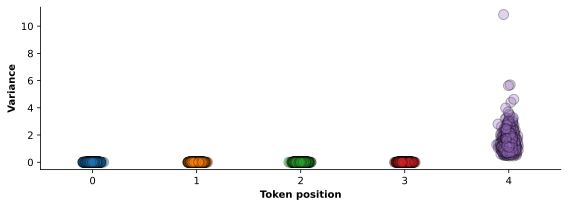

In [6]:
plt.figure(figsize=(8,3))

for i in range(batch.shape[1]):
  hs = outs.hidden_states[3][:,i,:]
  plt.plot(np.random.normal(i,.03,hs.shape[1]),hs.var(dim=0),'o',
           markeredgecolor='k',markersize=10,alpha=.3)

plt.gca().set(xlabel='Token position',ylabel='Variance',
              xticks=range(5),xlim=[-.5,4.5])

plt.tight_layout()
plt.savefig('ch5_proj25_part1.png')
plt.show()

# **Part 2: Cosine similarities in one layer**

(34, 1)


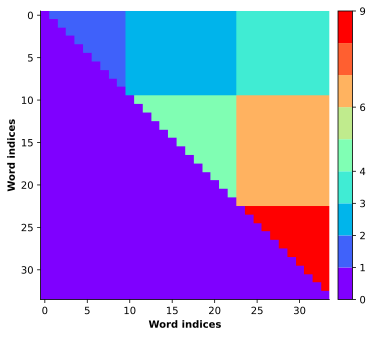

In [7]:
# vector of word categories
labels = np.array([[w[0] for w in words]]).T
print(labels.shape)

# mask for cosine similarity matrix
cat_mask = np.triu( labels@labels.T ,1)

# create a discrete colormap
N = cat_mask.max()
base = plt.get_cmap('rainbow')
cmapN = base.from_list(None,base(np.linspace(0,1,N)),N)

plt.imshow(cat_mask,cmap=cmapN)
plt.gca().set(xlabel='Word indices',ylabel='Word indices')
plt.colorbar(ticks=np.unique(cat_mask),pad=.02)

plt.tight_layout()
plt.savefig('ch5_proj25_part2a.png')
plt.show()

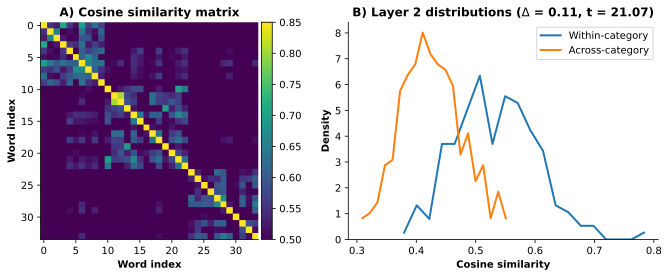

In [8]:
layeri = 2
hs = outs.hidden_states[layeri][:,-1,:]
hs /= torch.linalg.norm(hs,axis=1,keepdims=True)
csMat = hs @ hs.T

# extract the unique values
within = torch.concatenate((csMat[cat_mask==1],csMat[cat_mask==4],csMat[cat_mask==9]))
across = torch.concatenate((csMat[cat_mask==2],csMat[cat_mask==3],csMat[cat_mask==6]))

# t-test
tval = ttest_ind(within,across).statistic

# histograms
yWithin,xWithin = torch.histogram(within,bins=20,density=True)
yAcross,xAcross = torch.histogram(across,bins=20,density=True)

_,axs = plt.subplots(1,2,figsize=(10,4))
h = axs[0].imshow(csMat,vmin=.5,vmax=.85)
plt.colorbar(h,ax=axs[0],pad=.01)
axs[0].set(xlabel='Word index',ylabel='Word index',title='A) Cosine similarity matrix')

axs[1].plot(xWithin[:-1],yWithin,linewidth=2,label='Within-category')
axs[1].plot(xAcross[:-1],yAcross,linewidth=2,label='Across-category')
axs[1].set(ylim=[0,None],xlabel='Cosine similarity',ylabel='Density',
           title=f'B) Layer {layeri} distributions ($\\Delta$ = {within.mean()-across.mean():.2f}, t = {tval:.2f})')
axs[1].legend()


plt.tight_layout()
plt.savefig('ch5_proj25_part2b.png')
plt.show()

# **Part 3: Laminar profiles**

In [9]:
num_hidden = len(outs.hidden_states)
# names of the layers, for the x-axis tick labels
layer_labels = ['Emb'] + [f'L{i}' for i in range(num_hidden-1)]

In [10]:
# initializations
dist_metrics = np.zeros((4,num_hidden))


for layeri in range(num_hidden):

  # cosine similarity matrix
  hs = outs.hidden_states[layeri][:,-1,:].squeeze()
  hs /= torch.linalg.norm(hs,axis=1,keepdims=True)
  csMat = hs @ hs.T

  # extract the similarity values
  w = torch.concatenate((csMat[cat_mask==1],csMat[cat_mask==4],csMat[cat_mask==9]))
  a = torch.concatenate((csMat[cat_mask==2],csMat[cat_mask==3],csMat[cat_mask==6]))

  # calculate the metrics
  dist_metrics[0,layeri] = w.mean()
  dist_metrics[1,layeri] = a.mean()
  dist_metrics[2,layeri] = w.mean()-a.mean()
  dist_metrics[3,layeri] = ttest_ind(w,a).statistic

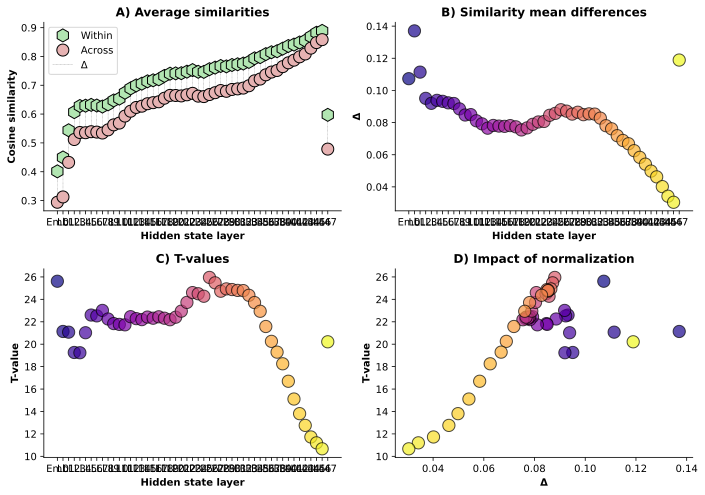

In [11]:
# show the results
_,axs = plt.subplots(2,2,figsize=(10,7))
axs[0,0].plot(dist_metrics[0,:],'kh',markerfacecolor=[.7,.9,.7],markersize=13,label='Within')
axs[0,0].plot(dist_metrics[1,:],'ko',markerfacecolor=[.9,.7,.7],markersize=12,label='Across')

# thin connecting lines representing \Delta
for i in range(1,num_hidden): # plot 0 separately for the legend
  axs[0,0].plot([i,i],dist_metrics[:2,i],'k:',linewidth=.3,zorder=-10)
axs[0,0].plot([0,0],dist_metrics[:2,0],'k:',linewidth=.3,zorder=-10,label='$\\Delta$')

axs[0,0].legend()
axs[0,0].set(xlabel='Hidden state layer',xticks=range(len(layer_labels)),xticklabels=layer_labels,
           ylabel='Cosine similarity',title='A) Average similarities')


axs[0,1].scatter(range(num_hidden),dist_metrics[2,:],s=150,edgecolor='k',
            c=plt.cm.plasma(np.linspace(0,1,num_hidden)),alpha=.7)
axs[0,1].set(xlabel='Hidden state layer',xticks=range(len(layer_labels)),xticklabels=layer_labels,
           ylabel='$\\mathbf{\\Delta}$',title='B) Similarity mean differences')

axs[1,0].scatter(range(num_hidden),dist_metrics[3,:],s=150,edgecolor='k',
            c=plt.cm.plasma(np.linspace(0,1,num_hidden)),alpha=.7)
axs[1,0].set(xlabel='Hidden state layer',xticks=range(len(layer_labels)),xticklabels=layer_labels,
           ylabel='T-value',title='C) T-values')

axs[1,1].scatter(dist_metrics[2,:],dist_metrics[3,:],s=150,edgecolor='k',
            c=plt.cm.plasma(np.linspace(0,1,num_hidden)),alpha=.7)
axs[1,1].set(xlabel='$\\mathbf{\\Delta}$',ylabel='T-value',title='D) Impact of normalization')


plt.tight_layout()
plt.savefig('ch5_proj25_part3.png')
plt.show()

In [12]:
for seqi in range(len(words)):

  # find max token
  maxtok = torch.argmax(outs.logits[seqi,-1,:],dim=-1)

  # build and print the sentence
  sentence = f'{tokenizer.decode(batch[seqi])}{tokenizer.decode(maxtok)}'
  print(sentence)

The next word is galaxy.
The next word is asteroid.
The next word is comet.
The next word is cosmos.
The next word is space.
The next word is sun.
The next word is planet.
The next word is moon.
The next word is star.
The next word is orbit.
The next word is ceiling.
The next word is sofa.
The next word is couch.
The next word is carpet.
The next word is door.
The next word is window.
The next word is lamp.
The next word is chair.
The next word is table.
The next word is rug.
The next word is bed.
The next word is floor.
The next word is wall.
The next word is pear.
The next word is grapefruit
The next word is banana.
The next word is cherry.
The next word is peach.
The next word is apple.
The next word is seed.
The next word is jelly.
The next word is orange.
The next word is lime.
The next word is fruit.


# **Part 4: Same words, different contexts**

In [13]:
# Note: Some variables here overwrite variables defined in earlier parts.

In [14]:
# GreatGatsby
url = 'https://www.gutenberg.org/cache/epub/64317/pg64317.txt'
text = requests.get(url).text
tokens = np.array( tokenizer.encode(text) )
print(f'There are {len(tokens):,} tokens, {len(set(tokens))} of which are unique.')

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (89263 > 1024). Running this sequence through the model will result in indexing errors


There are 89,263 tokens, 8151 of which are unique.


In [15]:
targets = [' years',' garage', ' lawn']

for i,w in enumerate(targets):

  # this token index
  t = tokenizer.encode(w)

  # find all the matches
  matches = np.where(tokens==t)[0]
  labels = np.full(len(matches),i+1)
  together = np.vstack((matches,labels)).T

  # stitch together
  if i==0:
    target_idxs = together
  else:
    target_idxs = np.vstack((target_idxs,together))

  # print count and confirm single-token words
  print(f'{w:>10} is token {t} and appears {sum(target_idxs[:,1]==(i+1))} times.')

     years is token [812] and appears 35 times.
    garage is token [15591] and appears 24 times.
      lawn is token [21133] and appears 27 times.


In [16]:
contextwin = 50

# create a batch
batch = torch.zeros((target_idxs.shape[0],contextwin+1),dtype=torch.long)


for i in range(target_idxs.shape[0]):
  toks = tokens[target_idxs[i,0]-contextwin:target_idxs[i,0]+1]
  batch[i,:] = torch.tensor(toks)

batch.shape

torch.Size([86, 51])

In [17]:
# show last few tokens in each sentence
for b in batch:
  print(tokenizer.decode(b[-5:]))

 younger and more vulnerable years
 since his New Haven years
’s three years
 aunt about a thousand years
 been after me for years
 that garage for eleven years
 person in his middle years

“Several years
, I am fifty years
 just eighteen, two years
 again for over four years

time in years
 He had waited five years
 a Chicago paper for years
t met for many years

“Five years
 pay
five years
t seen me for years
ook me just three years
 be my best friend years
 Almost
five years
Cody was fifty years
shores for five years
ot out those five years
 had obliterated four years
 autumn night, five years
 and the next thirty years
 about it for ten years
 this fellow for five years
 been neighbours for four years
“Twelve years

After two years
 to see me two years
’m five years
 anyone. For forty years
 this shadow of a garage
 impatiently around the garage
 so remarkable in the garage
 been living over that garage
 straining at the garage
 heard of making a garage
’s a garage
 the windows ove

# **Part 5: Within- and across-word similarities**

In [ ]:
# forward pass (~25 sec on CPU)
with torch.no_grad():
  outs = model(batch)

outs.hidden_states[3].shape

In [ ]:
# extract embeddings vectors for final token
activations = outs.hidden_states[3][:,-1,:]

# mask for cosine similarity matrix
cat_mask = np.triu( target_idxs[:,[1]]@target_idxs[:,[1]].T ,1)

plt.imshow(cat_mask)
plt.gca().set(xlabel='Sequence index',ylabel='Sequence index')
plt.colorbar(pad=.02)

plt.tight_layout()
plt.savefig('ch5_proj25_part5a.png')
plt.show()

In [ ]:
# cosine similarity matrix for one layer
layeri = 4
hs = outs.hidden_states[layeri][:,-1,:]
hs /= torch.linalg.norm(hs,axis=1,keepdims=True)
csMat = hs @ hs.T

# extract the block-wise data
within = torch.concatenate((csMat[cat_mask==1],csMat[cat_mask==4],csMat[cat_mask==9]))
acros1 = torch.concatenate((csMat[cat_mask==2],csMat[cat_mask==3]))
acros2 = csMat[cat_mask==6]

# distributions
yWithin,xWithin = torch.histogram(within,bins=30,density=True)
yAcros1,xAcros1 = torch.histogram(acros1,bins=30,density=True)
yAcros2,xAcros2 = torch.histogram(acros2,bins=30,density=True)


# show the similarity matrix
_,axs = plt.subplots(1,2,figsize=(10,4))
h = axs[0].imshow(csMat,vmin=.5,vmax=1)
plt.colorbar(h,ax=axs[0],pad=.01)
axs[0].set(xlabel='Word index',ylabel='Word index',title='Cosine similarity matrix')

# and the distributions
axs[1].plot(xWithin[:-1],yWithin,linewidth=2,label='Within-category')
axs[1].plot(xAcros1[:-1],yAcros1,linewidth=2,label='<years,garage/lawn>')
axs[1].plot(xAcros2[:-1],yAcros2,linewidth=2,label='<garage,lawn>')
axs[1].set(ylim=[0,None],xlabel='Cosine similarity',ylabel='Density',
           title=f'Layer {layeri} distributions')
axs[1].legend()

plt.tight_layout()
plt.savefig('ch5_proj25_part5b.png')
plt.show()

# **Part 6: Laminar profiles of similarity distributions**

In [ ]:
# common histogram bins for all distributions
binedges = torch.linspace(.4,1,35)
dx = binedges[1]-binedges[0]

# initialize: grouping X layer X bin
cs_dists = torch.zeros((3,num_hidden,len(binedges)-1))

# loop over layers
for layeri in range(num_hidden):

  # calculate the similarity matrix
  hs = outs.hidden_states[layeri][:,-1,:]
  hs /= torch.linalg.norm(hs,axis=1,keepdims=True)
  csMat = hs @ hs.T

  # extract the category elements
  within = torch.concatenate((csMat[cat_mask==1],csMat[cat_mask==4],csMat[cat_mask==9]))
  acros1 = torch.concatenate((csMat[cat_mask==2],csMat[cat_mask==3]))
  acros2 = csMat[cat_mask==6]

  # calculate the histograms
  cs_dists[0,layeri,:],_ = torch.histogram(within,bins=binedges,density=True)
  cs_dists[1,layeri,:],_ = torch.histogram(acros1,bins=binedges,density=True)
  cs_dists[2,layeri,:],_ = torch.histogram(acros2,bins=binedges,density=True)


# transform from density to probability/dx
cs_dists *= dx

In [ ]:
# the tornado plots :D
_,axs = plt.subplots(1,3,figsize=(12,4))

titles = [ 'Within','<years,garage/lawn>','<lawn,garage>' ]

# generate the plots
for i in range(3):
  h = axs[i].imshow(cs_dists[i,:,:],vmin=0,vmax=.25,aspect='auto',origin='lower',
                extent=[binedges[0],binedges[-1],0,num_hidden],cmap='magma')
  plt.colorbar(h,ax=axs[i],orientation='horizontal',location='top',pad=.01)
  axs[i].set(xlabel='Cosine similarity',ylabel='Hidden layer')
  axs[i].set_title(titles[i]+'\n\n\n',fontweight='bold')

plt.tight_layout()
plt.savefig('ch5_proj25_part6.png')
plt.show()